# Session 02 · Can ResNet-18 learn Food-101 from scratch?

I’m using a Colab GPU so I can train on every eligible photo at 224 × 224. This is the first point of comparison for transfer learning. In later sessions I can keep the architecture and split fixed while changing the starting weights or the layers allowed to learn.

In Colab, choose a GPU in **Runtime → Change runtime type**, then **Run all**. The first run stages Food-101 on the runtime’s own disk. Drive holds the audit, dataset archive and epoch checkpoints. Reconnecting to a new runtime and running the notebook again resumes the latest completed epoch. Use one active training runtime for this experiment.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime for full training, then run again.")
device = torch.device("cuda")
print("Training GPU:", torch.cuda.get_device_name(device))

Training GPU: Tesla T4


In [4]:
from pathlib import Path
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Colab Notebooks/Project 03 - Intelligent Food and Retail Product Recognition")
    sys.path.insert(0, str(PROJECT))
    from colab_food101 import stage_food
    ROOT = stage_food(PROJECT, Path("/content/project03_data"))
else:
    PROJECT = Path.cwd()
    ROOT = PROJECT / "Dataset/food-101"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the same photos as every later model

I verify the saved manifest fingerprint before building the loaders. A class map gives each dish a stable output index. Validation uses the same 100 images per dish for every run. I use a 224-pixel center crop at validation time. Training uses a random crop covering at least 70% of the original area and a possible horizontal flip so the classifier sees modest changes in framing. I keep the three ImageNet normalization constants per channel for the future pretrained comparison. [ResNet-18 input recipe](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

In [5]:
import hashlib
import json
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights

artifacts = PROJECT / "Artifacts"
manifest_path = artifacts / "split_manifest.csv"
fingerprint = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
assert fingerprint == "86555fa81dd85aebd59d725ab89148a8a7596430889094e4566f917fe6f451fc"
table = pd.read_csv(manifest_path)
class_map = json.loads((artifacts / "class_map.json").read_text())
assert table.dish.map(class_map).eq(table.class_id).all()
classes = sorted(class_map, key=class_map.get)
assert len(classes) == 101 and [class_map[k] for k in classes] == list(range(101))
train_rows = table.loc[table.split.eq("train")]
val_rows = table.loc[table.split.eq("validation")]
assert (len(train_rows), len(val_rows)) == (65624, 10100)
eval_transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
train_transform = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                             T.ToTensor(), T.Normalize(eval_transform.mean, eval_transform.std)])

class Photos(Dataset):
    def __init__(self, rows, transform):
        self.records = list(rows[["path", "class_id"]].itertuples(index=False, name=None))
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(ROOT / path) as photo:
            return self.transform(photo.convert("RGB")), label

train_set = Photos(train_rows, train_transform)
val_set = Photos(val_rows, eval_transform)
BATCH = 64
WORKERS = 2
SEED = 42
def loader(dataset, training, epoch=0):
    generator = torch.Generator().manual_seed(SEED + epoch)
    return DataLoader(dataset, batch_size=BATCH, shuffle=training, generator=generator,
                      num_workers=WORKERS, pin_memory=device.type == "cuda")

print(len(train_set), "training photos and", len(val_set), "validation photos")

65624 training photos and 10100 validation photos


## Look inside a residual block

The main branch learns a correction to its input. A **skip connection** carries the input around that branch so the block can add the two tensors before applying ReLU. I inspect one real training image and verify the addition numerically. ResNet-18 makes this easy to follow. The InceptionV3 Food-101 project uses parallel filters at different scales. The MobileNetV3 reference uses a lighter network designed for efficient inference. [InceptionV3 example](https://github.com/DucLeTrong/food101-classification) · [MobileNetV3 example](https://github.com/yueyang-yin/food-101)

In [6]:
def new_model():
    torch.manual_seed(SEED)
    return resnet18(weights=None, num_classes=len(classes)).to(device)

model = new_model().eval()
with torch.no_grad():
    x = train_set[0][0].unsqueeze(0).to(device)
    stem = model.maxpool(model.relu(model.bn1(model.conv1(x))))
    block = model.layer1[0]
    correction = block.bn2(block.conv2(block.relu(block.bn1(block.conv1(stem)))))
    torch.testing.assert_close(block(stem), torch.relu(correction + stem))
print("Skip input and learned correction:", tuple(stem.shape), tuple(correction.shape))

Skip input and learned correction: (1, 64, 56, 56) (1, 64, 56, 56)


## Time the GPU before setting the epoch budget

I use SGD with momentum at a fixed learning rate to make this first baseline easy to reproduce. AdamW is a reasonable alternative. A learning-rate scheduler is a later experiment. Mixed precision uses lower precision for suitable GPU operations, and a gradient scaler helps prevent small gradients from disappearing. I warm up three batches and time twelve on a disposable model. The measured rate gives me a provisional epoch count targeting 60 minutes of training, capped at ten epochs. Validation and saving add time. The training model starts fresh.

In [7]:
LR = 0.03
TIME_BUDGET_MIN = 60
MAX_EPOCHS = 10
use_amp = device.type == "cuda"
def optimizer_for(net):
    return torch.optim.SGD(net.parameters(), lr=LR, momentum=0.9, weight_decay=1e-4)

def train_batch(net, optimizer, scaler, batch):
    images, labels = (value.to(device, non_blocking=True) for value in batch)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, enabled=use_amp):
        loss = nn.functional.cross_entropy(net(images), labels)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return loss.detach(), len(labels)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def measure():
    probe = new_model().train()
    opt = optimizer_for(probe)
    scale = torch.amp.GradScaler(device.type, enabled=use_amp)
    batches = iter(loader(train_set, True))
    for _ in range(3):
        train_batch(probe, opt, scale, next(batches))
    synchronize()
    start = time.perf_counter()
    count = 0
    for _ in range(12):
        _, n = train_batch(probe, opt, scale, next(batches))
        count += n
    synchronize()
    return count / (time.perf_counter() - start)

run_dir = artifacts / "session02_resnet18_scratch"
run_dir.mkdir(exist_ok=True)
latest = run_dir / "latest.pt"
config = dict(manifest=fingerprint, architecture="resnet18", initial_weights="random",
              seed=SEED, batch=BATCH, crop=224, lr=LR, momentum=0.9, weight_decay=1e-4,
              workers=WORKERS, mixed_precision=use_amp, recipe=1)
checkpoint = torch.load(latest, map_location="cpu", weights_only=True) if latest.exists() else None
if checkpoint is None:
    rate = measure()
    minutes = len(train_set) / rate / 60
    epochs = max(1, min(MAX_EPOCHS, int(TIME_BUDGET_MIN / minutes)))
    budget = dict(images_per_second=rate, estimated_train_minutes_per_epoch=minutes, epochs=epochs,
                  device=torch.cuda.get_device_name() if use_amp else "CPU",
                  torch=str(torch.__version__), torchvision=str(torchvision.__version__))
else:
    if checkpoint["config"] != config:
        raise ValueError("The saved run uses a different configuration. Use a separate run directory.")
    budget = checkpoint["budget"]
print(budget)

{'images_per_second': 202.84537257781898, 'estimated_train_minutes_per_epoch': 5.391956047278017, 'epochs': 10, 'device': 'Tesla T4', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130'}


## Train and select by validation macro F1

Top-1 counts a hit when the first prediction is right. Top-5 gives credit when the correct dish appears among the five highest scores. Macro F1 computes F1 for each dish, then gives all 101 dishes equal weight. I keep the epoch with the highest validation macro F1. The latest checkpoint includes the current weights, optimizer momentum, gradient scaler, history and best weights together, so a disconnect between epochs can be recovered by running the notebook again.

In [8]:
def evaluate(net, batches):
    net.eval()
    pairs, top5, total_loss = [], 0, 0.0
    with torch.inference_mode():
        for images, labels in batches:
            images, labels = images.to(device), labels.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = net(images)
                loss = nn.functional.cross_entropy(logits, labels, reduction="sum")
            top = logits.topk(5, dim=1).indices
            top5 += int(top.eq(labels[:, None]).any(dim=1).sum())
            pairs.append(torch.stack([labels, top[:, 0]], dim=1).cpu())
            total_loss += loss.item()
    pairs = torch.cat(pairs)
    k = len(classes)
    matrix = torch.bincount(pairs[:, 0] * k + pairs[:, 1], minlength=k*k).reshape(k, k)
    hits = matrix.diag()
    per_f1 = 2 * hits / (matrix.sum(0) + matrix.sum(1)).clamp_min(1)
    return dict(val_loss=total_loss / len(pairs), top1=hits.sum().item() / len(pairs),
                top5=top5 / len(pairs), macro_f1=per_f1.mean().item()), matrix

def save_checkpoint(value, path):
    pending = path.with_suffix(".pending")
    torch.save(value, pending)
    pending.replace(path)

def train_epochs(stop_epoch):
    net = new_model()
    opt = optimizer_for(net)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    state = torch.load(latest, map_location="cpu", weights_only=True) if latest.exists() else None
    history, best = [], None
    if state:
        if state["config"] != config or state["budget"] != budget:
            raise ValueError("Checkpoint configuration changed.")
        net.load_state_dict(state["model"])
        opt.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        history, best = state["history"], state["best"]
        del state
    for epoch in range(len(history) + 1, stop_epoch + 1):
        torch.manual_seed(SEED + epoch)
        start = time.perf_counter()
        net.train()
        loss_sum = torch.zeros((), device=device)
        count = 0
        for batch in loader(train_set, True, epoch):
            loss, n = train_batch(net, opt, scaler, batch)
            loss_sum += loss * n
            count += n
        assert count == len(train_set)
        train_loss = loss_sum.item() / count
        scores, matrix = evaluate(net, loader(val_set, False))
        assert matrix.sum().item() == len(val_set)
        row = dict(epoch=epoch, train_loss=train_loss, seconds=time.perf_counter()-start, **scores)
        if not all(math.isfinite(v) for v in row.values()):
            raise ValueError(f"Non-finite result at epoch {epoch}: {row}")
        history.append(row)
        if best is None or scores["macro_f1"] > best["macro_f1"]:
            best = dict(epoch=epoch, macro_f1=scores["macro_f1"], matrix=matrix,
                        weights={k: v.detach().cpu().clone() for k,v in net.state_dict().items()})
        save_checkpoint(dict(model=net.state_dict(), optimizer=opt.state_dict(), scaler=scaler.state_dict(),
                             config=config, history=history, best=best, budget=budget), latest)
        print(f"Epoch {epoch}/{stop_epoch}: {row}", flush=True)
    return history, best

history, best = train_epochs(budget["epochs"])

Epoch 1/10: {'epoch': 1, 'train_loss': 4.1353268240277945, 'seconds': 428.88346916699993, 'val_loss': 3.913608919653562, 'top1': 0.11158415841584159, 'top5': 0.31603960396039604, 'macro_f1': 0.0842670202255249}
Epoch 2/10: {'epoch': 2, 'train_loss': 3.5216477108222604, 'seconds': 410.7390403889999, 'val_loss': 3.348732008225847, 'top1': 0.20663366336633662, 'top5': 0.46574257425742577, 'macro_f1': 0.18581286072731018}
Epoch 3/10: {'epoch': 3, 'train_loss': 3.067554838930879, 'seconds': 402.52430563999997, 'val_loss': 3.2407340644609812, 'top1': 0.23554455445544553, 'top5': 0.49653465346534653, 'macro_f1': 0.21115747094154358}
Epoch 4/10: {'epoch': 4, 'train_loss': 2.673171924524564, 'seconds': 384.8771421749998, 'val_loss': 2.746758060266476, 'top1': 0.3297029702970297, 'top5': 0.6218811881188119, 'macro_f1': 0.3176113963127136}
Epoch 5/10: {'epoch': 5, 'train_loss': 2.35663257725832, 'seconds': 375.270518583, 'val_loss': 2.356118207497172, 'top1': 0.4161386138613861, 'top5': 0.6994059

## Reload the selected epoch and inspect errors

I check that the saved weights reproduce the validation confusion matrix, then find the most frequent directed error. A directed error counts cases such as ramen predicted as pho separately from pho predicted as ramen. The curves, matrix, scores and example paths give the next session specific errors to revisit.

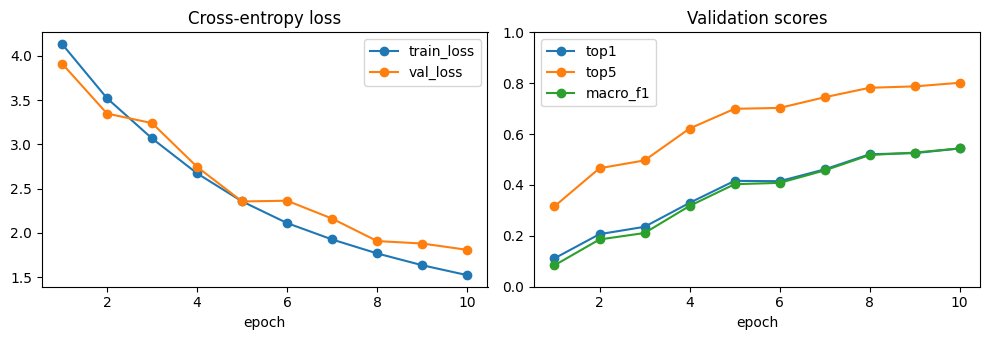

Selected epoch 10 {'val_loss': 1.8094881514747545, 'top1': 0.5435643564356436, 'top5': 0.8016831683168317, 'macro_f1': 0.5437070727348328}
Most frequent validation error: {'actual': 'greek_salad', 'predicted': 'caprese_salad', 'count': 27, 'examples': ['images/greek_salad/1201225.jpg', 'images/greek_salad/1265190.jpg', 'images/greek_salad/1486851.jpg', 'images/greek_salad/1733988.jpg', 'images/greek_salad/1792473.jpg']}


In [9]:
selected = new_model()
selected.load_state_dict(best["weights"])
scores, matrix = evaluate(selected, loader(val_set, False))
assert torch.equal(matrix, best["matrix"]), "Reloaded validation predictions changed the confusion matrix."
errors = matrix.clone()
errors.fill_diagonal_(0)
worst = None
if errors.max() > 0:
    true_id, pred_id = divmod(int(errors.argmax()), len(classes))
    worst = dict(actual=classes[true_id], predicted=classes[pred_id], count=int(errors.max()))
    candidates = val_rows[val_rows.class_id.eq(true_id)]
    examples = []
    pos = 0
    with torch.inference_mode():
        for images, _ in loader(Photos(candidates, eval_transform), False):
            with torch.autocast(device_type=device.type, enabled=use_amp):
                predicted = selected(images.to(device)).topk(5, dim=1).indices[:, 0].cpu()
            for offset in (predicted == pred_id).nonzero().flatten().tolist():
                examples.append(candidates.iloc[pos + offset].path)
            pos += len(images)
    worst["examples"] = examples[:5]

save_checkpoint(dict(weights=best["weights"], classes=classes, config=config, epoch=best["epoch"]),
                run_dir / "best.pt")
summary = dict(config=config, budget=budget, selected_epoch=best["epoch"], validation=scores,
               top_confusion=worst, history=history, class_order=classes, confusion_matrix=matrix.tolist())
pending = run_dir / "validation.json.tmp"
pending.write_text(json.dumps(summary, indent=2), encoding="utf-8")
pending.replace(run_dir / "validation.json")
frame = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
frame[["train_loss", "val_loss"]].plot(ax=axes[0], marker="o", title="Cross-entropy loss")
frame[["top1", "top5", "macro_f1"]].plot(ax=axes[1], marker="o", ylim=(0,1), title="Validation scores")
fig.tight_layout()
fig.savefig(run_dir / "learning_curves.png")
plt.show()
print("Selected epoch", best["epoch"], scores)
print("Most frequent validation error:", worst)